### Import libraries

In [13]:
import os
import sys
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']

In [2]:
# PyCOMET
PyCOMET = WORKSPACE + '/ML/PyCOMET/pycomet/'
if importlib.util.find_spec('pycomet') is None:
    sys.path.append(os.path.abspath(PyCOMET))

In [3]:
# SurQCT
SurQCT = '/home/zanardi/Workspace/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))

from surqct import config as cfg

### Analysis of the input features

In [25]:
# Output folder
path = cfg.paths.MERuns + 'database/levels/modified/O3_UMN/O2/VMin_VMax_log10.csv'
data_in = pd.read_csv(path)

In [26]:
def plot_hist(dist, n_bins, xlabel):
    fig, ax = plt.subplots(tight_layout=True)
    ax.hist(dist, bins=n_bins)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Num. states')
    plt.show()

n_bins = 100

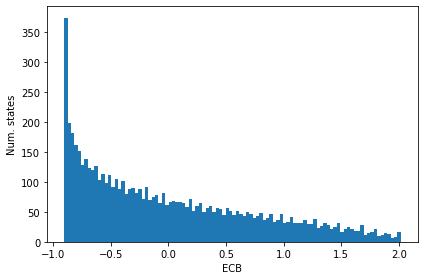

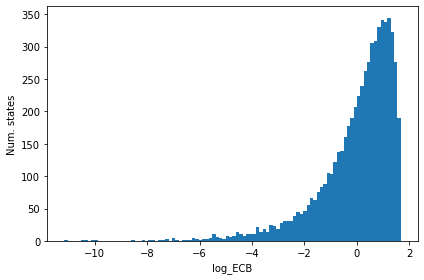

In [28]:
for k in ('ECB','log_ECB'):
    x = data_in[k].to_numpy().reshape(-1)
    mean, var = tf.nn.moments(x, axes=0)
    x = (x-mean)/var
    plot_hist(x, n_bins, k)